# Supplementary Figure 4

Peptide-length sensitivity of FastaLake results. Every production search was repeated with a minimum peptide length of seven residues; the panels compare the new searches, and the production results filtered to at least 7 or 9 residues, with the published 5-50-residue results. The composite is drawn in one figure, as the v30 build drew it, and each panel below is a crop of it.

Run from the repository root: `python paper.py build SFig04`. Pixel-exact text needs `FASTALAKE_FONT_DIR` with the Söhne fonts (including `soehne-buch.ttf`).

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()
from IPython.display import Image, display
D = panels.load(SD)

## Panel a

Per-acquisition peptide gain of public-sequence FastaLake over the specimen-matched metagenome (MG) database, at 5-50 residues, in the new 7-50 searches and filtered to 9-50. Supports visible_v30f line 398: "reduced the median gains to 14.5% (PREDICT) and 45.0% (CapScan)" and "showed gains of 67% and 96%". n = 296 PREDICT and 282 CapScan acquisitions (matched pairs). No test; bars are medians of per-acquisition ratios. Values above 250% are drawn at 250% and counted.

  [style] SFig04_raw: 0 label(s) raised to 5 pt, 14 capped to 7 pt, 0 tick axis/axes clamped, 4 line(s) raised to 1 pt


<repo>/figures/SFig04/panels.py:426: UserWarning: SFig04_raw.pdf is 160.00 mm wide, not 88 or 180 mm (nearest 180). compose.py will refuse it. If it is a near miss, the cause is almost always a bbox that cropped the canvas -- REDRAW at the placed width; do not scale and do not pad.
  fl.save(fig, raw, dpi=PNG_DPI, formats=('pdf',))


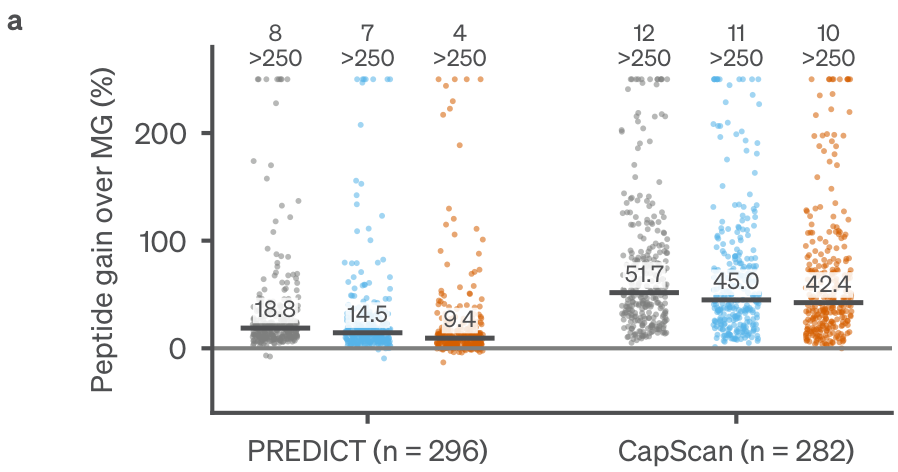

panel  cohort population        item sample   x     value   plotted   label
    a PREDICT  baseline5 n_above_250    NaN 0.0  8.000000       NaN  8 >250
    a PREDICT  baseline5      median    NaN 0.0 18.754795 18.754795    18.8
    a PREDICT     fresh7 n_above_250    NaN 1.0  7.000000       NaN  7 >250
    a PREDICT     fresh7      median    NaN 1.0 14.455684 14.455684    14.5
    a PREDICT    nested9 n_above_250    NaN 2.0  4.000000       NaN  4 >250
    a PREDICT    nested9      median    NaN 2.0  9.386055  9.386055     9.4
    a CAPSCAN  baseline5 n_above_250    NaN 4.0 12.000000       NaN 12 >250
    a CAPSCAN  baseline5      median    NaN 4.0 51.738530 51.738530    51.7
    a CAPSCAN     fresh7 n_above_250    NaN 5.0 11.000000       NaN 11 >250
    a CAPSCAN     fresh7      median    NaN 5.0 44.972189 44.972189    45.0
    a CAPSCAN    nested9 n_above_250    NaN 6.0 10.000000       NaN 10 >250
    a CAPSCAN    nested9      median    NaN 6.0 42.448173 42.448173    42.4
PREDICT base

In [2]:
p = panels.save_panel('a', SD, OUT)
display(Image(filename=str(p)))
print(panels.plotted('a', OUT).query("item != 'acquisition'").to_string(index=False))
for k in ['PREDICT', 'CAPSCAN']:
    for p in panels.POPS_AB:
        print(k, p, panels.stat_ab_matched(D, k, p))
for k in ['PREDICT', 'CAPSCAN']:
    print(k, '5-8 residues', panels.stat_gain_5_8(D, k))

## Panel b

Recovery of MG-search peptide identities by the FastaLake search. Supports visible_v30f line 398: "identity recovery remained 85.4% and 84.0%". n = 296 PREDICT and 282 CapScan acquisitions. No test; medians.

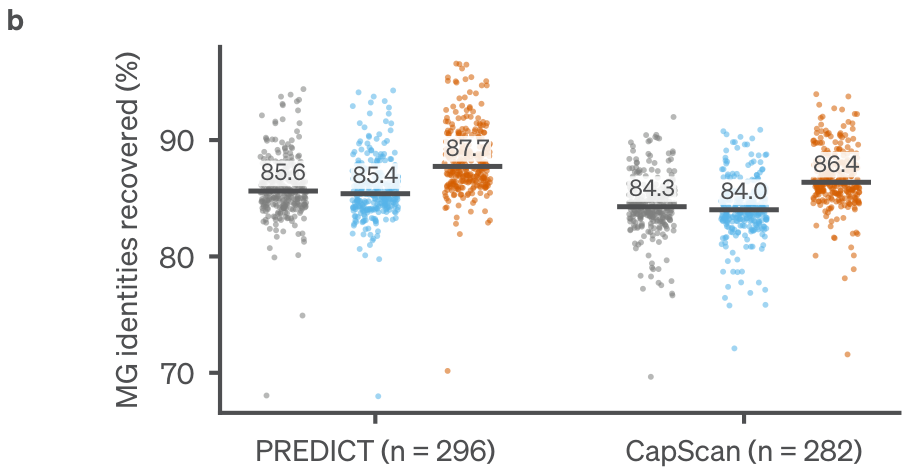

panel  cohort population   item sample   x     value   plotted label
    b PREDICT  baseline5 median    NaN 0.0 85.618310 85.618310  85.6
    b PREDICT     fresh7 median    NaN 1.0 85.391859 85.391859  85.4
    b PREDICT    nested9 median    NaN 2.0 87.732459 87.732459  87.7
    b CAPSCAN  baseline5 median    NaN 4.0 84.272429 84.272429  84.3
    b CAPSCAN     fresh7 median    NaN 5.0 84.012979 84.012979  84.0
    b CAPSCAN    nested9 median    NaN 6.0 86.372613 86.372613  86.4


In [3]:
p = panels.save_panel('b', SD, OUT)
display(Image(filename=str(p)))
print(panels.plotted('b', OUT).query("item != 'acquisition'").to_string(index=False))

## Panel c

Median change in accepted peptides relative to 5-50 residues after filtering to 7-50 residues or re-searching at 7-50, by database. CapScan FL uses the v28f roster of 347 acquisitions; CapScan MG has 282 (no metagenome for participant 15). Unit: acquisition. No test; medians.

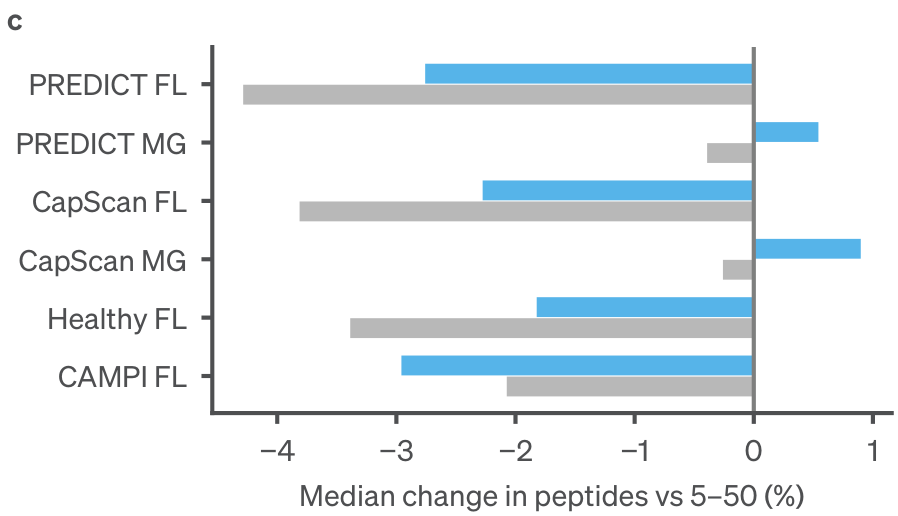

panel  cohort population       item sample     x     value   plotted label
    c PREDICT    nested7 PREDICT FL    NaN  0.18 -4.285890 -4.285890   NaN
    c PREDICT     fresh7 PREDICT FL    NaN -0.18 -2.758221 -2.758221   NaN
    c PREDICT    nested7 PREDICT MG    NaN  1.18 -0.391915 -0.391915   NaN
    c PREDICT     fresh7 PREDICT MG    NaN  0.82  0.542292  0.542292   NaN
    c CAPSCAN    nested7 CapScan FL    NaN  2.18 -3.812141 -3.812141   NaN
    c CAPSCAN     fresh7 CapScan FL    NaN  1.82 -2.275760 -2.275760   NaN
    c CAPSCAN    nested7 CapScan MG    NaN  3.18 -0.259056 -0.259056   NaN
    c CAPSCAN     fresh7 CapScan MG    NaN  2.82  0.898207  0.898207   NaN
    c  HSTOOL    nested7 Healthy FL    NaN  4.18 -3.387060 -3.387060   NaN
    c  HSTOOL     fresh7 Healthy FL    NaN  3.82 -1.822065 -1.822065   NaN
    c   CAMPI    nested7   CAMPI FL    NaN  5.18 -2.073248 -2.073248   NaN
    c   CAMPI     fresh7   CAMPI FL    NaN  4.82 -2.957762 -2.957762   NaN
PREDICT FL {'n': 306, 'fi

In [4]:
p = panels.save_panel('c', SD, OUT)
display(Image(filename=str(p)))
print(panels.plotted('c', OUT).query("item != 'acquisition'").to_string(index=False))
for co, arm, lab in panels.C_ARMS:
    print(lab, panels.stat_c_median_change(D, co, arm))

## Panel d

Pooled member-specific peptides for the three least represented CAMPI members in FastaLake (FL), MG and reference searches, with 0.5 added for the logarithmic axis. Legend, visible_v30f line 225. Unit: peptide, pooled over 15 acquisitions. No test.

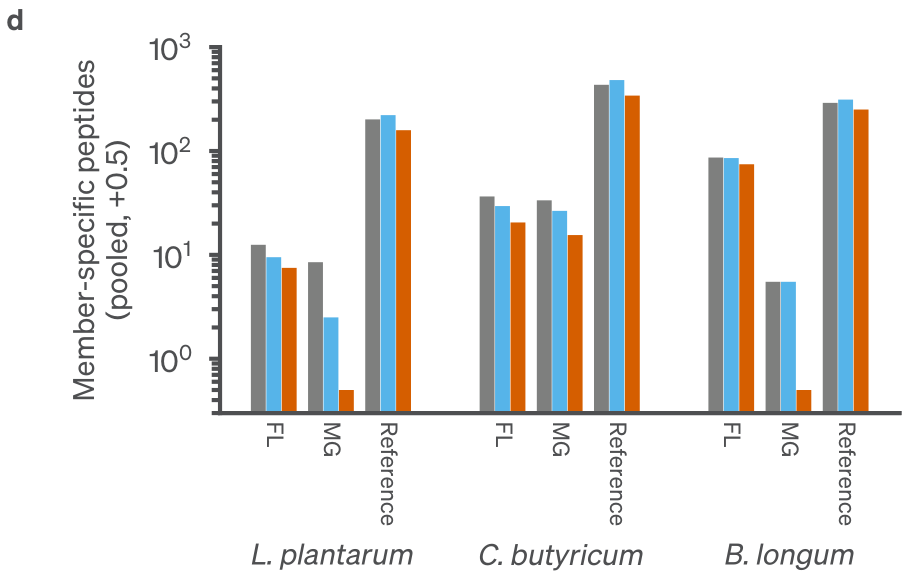

panel cohort population                                 item sample     x  value  plotted label
    d  CAMPI  baseline5  Lactobacillus plantarum | FastaLake    NaN -0.27   12.0     12.5   NaN
    d  CAMPI     fresh7  Lactobacillus plantarum | FastaLake    NaN  0.00    9.0      9.5   NaN
    d  CAMPI    nested9  Lactobacillus plantarum | FastaLake    NaN  0.27    7.0      7.5   NaN
    d  CAMPI  baseline5 Lactobacillus plantarum | Metagenome    NaN  0.73    8.0      8.5   NaN
    d  CAMPI     fresh7 Lactobacillus plantarum | Metagenome    NaN  1.00    2.0      2.5   NaN
    d  CAMPI    nested9 Lactobacillus plantarum | Metagenome    NaN  1.27    0.0      0.5   NaN
    d  CAMPI  baseline5  Lactobacillus plantarum | Reference    NaN  1.73  201.0    201.5   NaN
    d  CAMPI     fresh7  Lactobacillus plantarum | Reference    NaN  2.00  221.0    221.5   NaN
    d  CAMPI    nested9  Lactobacillus plantarum | Reference    NaN  2.27  158.0    158.5   NaN
    d  CAMPI  baseline5    Clostridium b

In [5]:
p = panels.save_panel('d', SD, OUT)
display(Image(filename=str(p)))
print(panels.plotted('d', OUT).query("item != 'acquisition'").to_string(index=False))
print(panels.stat_d_fold_ref_over_fl(D))

## Panel e

CAMPI fusion-control diagnostic (paired estimate plus unpaired worst case) at peptide q ≤ 0.01, pooled over 15 acquisitions per control seed. Dashed line, 1%. The pooled values are recomputed below from the 150 per-acquisition rows. No test.

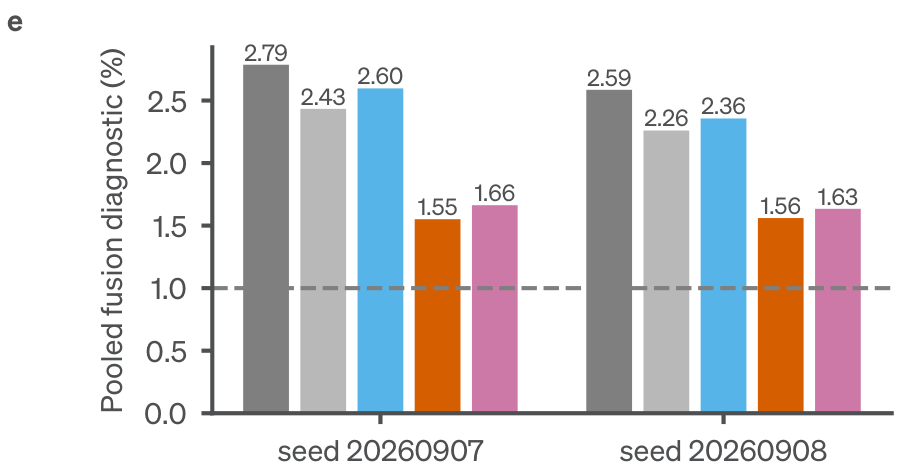

panel cohort     population          item sample    x    value  plotted label
    e  CAMPI      baseline5 seed 20260907    NaN  0.0 2.786226 2.786226  2.79
    e  CAMPI        nested7 seed 20260907    NaN  1.0 2.433311 2.433311  2.43
    e  CAMPI         fresh7 seed 20260907    NaN  2.0 2.596690 2.596690  2.60
    e  CAMPI        nested9 seed 20260907    NaN  3.0 1.551344 1.551344  1.55
    e  CAMPI fresh7_nested9 seed 20260907    NaN  4.0 1.663153 1.663153  1.66
    e  CAMPI      baseline5 seed 20260908    NaN  6.0 2.585750 2.585750  2.59
    e  CAMPI        nested7 seed 20260908    NaN  7.0 2.260267 2.260267  2.26
    e  CAMPI         fresh7 seed 20260908    NaN  8.0 2.356564 2.356564  2.36
    e  CAMPI        nested9 seed 20260908    NaN  9.0 1.560418 1.560418  1.56
    e  CAMPI fresh7_nested9 seed 20260908    NaN 10.0 1.634282 1.634282  1.63
       seed    search  min_residues  acq       n   num   unp  recomputed_pct  pooled_diag_pct      abs_diff
0  20260907  baseline             

In [6]:
p = panels.save_panel('e', SD, OUT)
display(Image(filename=str(p)))
print(panels.plotted('e', OUT).query("item != 'acquisition'").to_string(index=False))
print(panels.stat_e_pooled_diagnostic(D).to_string())

## Panel f

Healthy-stool searches against the common FASTA or in the joint search, relative to each acquisition's own database (58 acquisitions). Labels: median peptide change and median fraction of own-database identities kept. Unit: acquisition. No test.

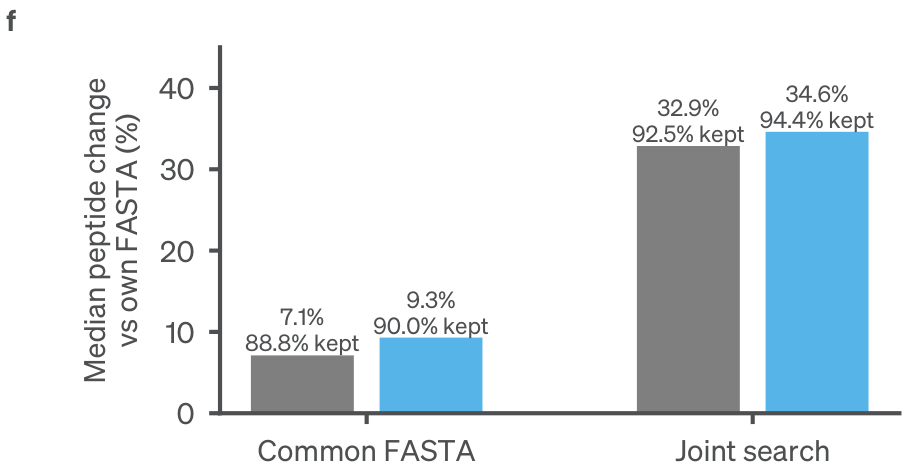

panel cohort population   item sample   x     value   plotted              label
    f HSTOOL  baseline5 common    NaN 0.0  7.114630  7.114630  7.1% / 88.8% kept
    f HSTOOL     fresh7 common    NaN 1.0  9.298374  9.298374  9.3% / 90.0% kept
    f HSTOOL  baseline5  joint    NaN 3.0 32.862964 32.862964 32.9% / 92.5% kept
    f HSTOOL     fresh7  joint    NaN 4.0 34.605670 34.605670 34.6% / 94.4% kept
common baseline5 {'n': 58, 'median_change_pct': 7.114629901394808, 'median_kept_pct': 88.76504954907861}
common fresh7 {'n': 58, 'median_change_pct': 9.298374463693872, 'median_kept_pct': 90.04712395340019}
joint baseline5 {'n': 58, 'median_change_pct': 32.86296392247042, 'median_kept_pct': 92.50383024971129}
joint fresh7 {'n': 58, 'median_change_pct': 34.60566958855773, 'median_kept_pct': 94.38778763352221}


In [7]:
p = panels.save_panel('f', SD, OUT)
display(Image(filename=str(p)))
print(panels.plotted('f', OUT).query("item != 'acquisition'").to_string(index=False))
for s in ['common', 'joint']:
    for p in ['baseline5', 'fresh7']:
        print(s, p, panels.stat_f_healthy(D, s, p))

## Panel g

Change in study-level protein groups under direct peptide assignment, new 7-50 search vs 5-50 baseline. CapScan on the v28f roster (347 acquisitions). Unit: protein group (one study-level grouping per bar). No test.

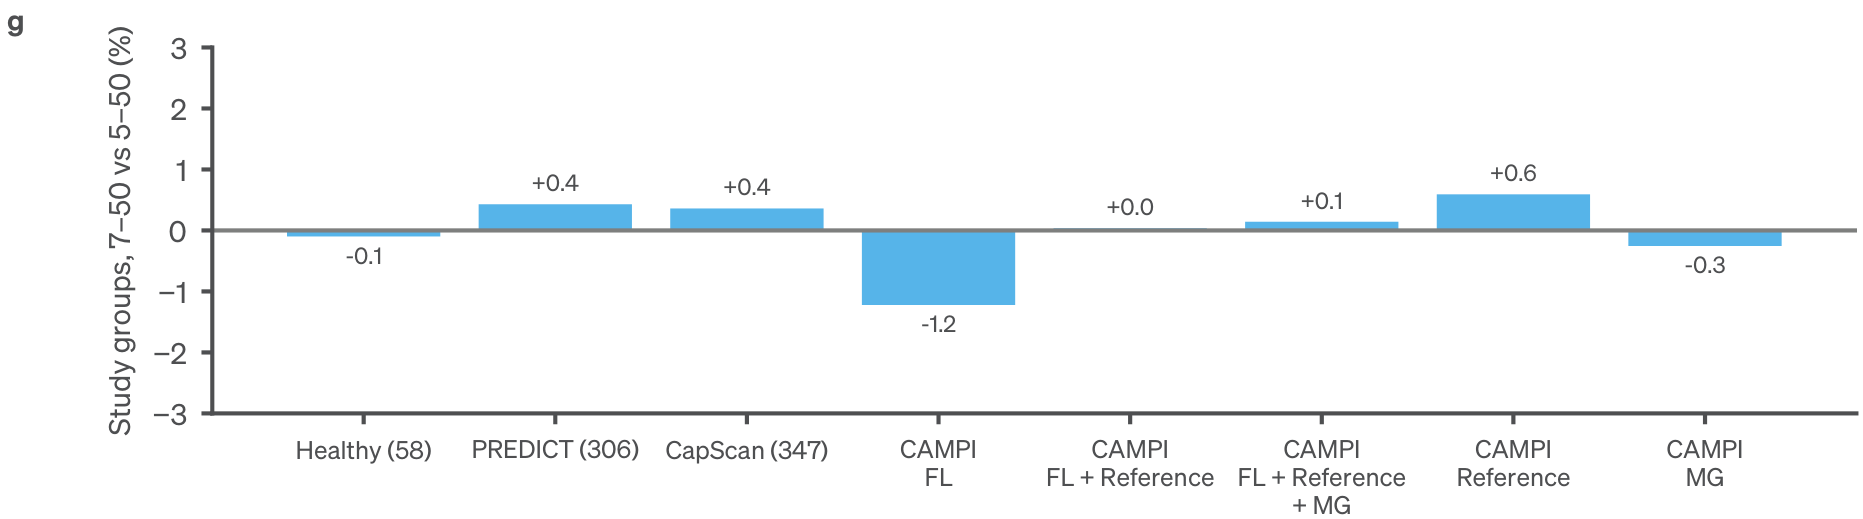

panel           cohort          population                      item sample   x     value   plotted label
    g   HSTOOL_noclust fresh7 vs baseline5              Healthy (58)    NaN 0.0 -0.099211 -0.099211  -0.1
    g  PREDICT_noclust fresh7 vs baseline5             PREDICT (306)    NaN 1.0  0.429249  0.429249  +0.4
    g  CAPSCAN_noclust fresh7 vs baseline5             CapScan (347)    NaN 2.0  0.360123  0.360123  +0.4
    g CAMPI_FL_UNIPROT fresh7 vs baseline5                  CAMPI FL    NaN 3.0 -1.222178 -1.222178  -1.2
    g     CAMPI_FL_REF fresh7 vs baseline5      CAMPI FL + Reference    NaN 4.0  0.035483  0.035483  +0.0
    g  CAMPI_FL_REF_MG fresh7 vs baseline5 CAMPI FL + Reference + MG    NaN 5.0  0.142717  0.142717  +0.1
    g        CAMPI_REF fresh7 vs baseline5           CAMPI Reference    NaN 6.0  0.592277  0.592277  +0.6
    g         CAMPI_MG fresh7 vs baseline5                  CAMPI MG    NaN 7.0 -0.254978 -0.254978  -0.3
CAMPI_FL_REF {'baseline': 11273, 'fresh7': 112

In [8]:
p = panels.save_panel('g', SD, OUT)
display(Image(filename=str(p)))
print(panels.plotted('g', OUT).query("item != 'acquisition'").to_string(index=False))
for t in D['gr'].task:
    print(t, panels.stat_g_change(D, t))

## Checks and numbers

Pixel check of the composite against the v30 render (expected/SFig04_v30.png), an exact comparison of the plotted values, and every recomputed number in NUMBERS.tsv order.

In [9]:
import filecmp
from tools.check_pixels import compare
b = panels.build_figure(SD, OUT)
print('plotted values identical to producer:', filecmp.cmp(b['plotted_values'], UNIT / 'expected' / 'SFig04_plotted_values.tsv', shallow=False))
print('smallest text (pt at placed size):', b['smallest_text_pt'], '; slanted labels:', b['slanted_labels'])
if not panels.FONTS_PRESENT:
    print('pixel checks SKIPPED: fonts absent')
else:
    r = compare(b['png'], UNIT / 'expected' / 'SFig04_v30.png', UNIT / 'checks' / 'SFig04_v30', dpi=panels.PNG_DPI)
    print('composite vs v30', r['verdict'], r.get('differing_pixels'))
for k, v in panels.numbers(SD):
    print(k, repr(v), sep='\t')

plotted values identical to producer: True
smallest text (pt at placed size): 5.04 ; slanted labels: 3


composite vs v30 IDENTICAL 0
L83 L. plantarum 5-50	'twelve'
L83 L. plantarum 9-50	'seven'
L83 fold min	3.372093023255814
L83 fold max	16.75
L239 searches	2022
L421 searches	2022
L421 standard	2017
L421 LFQ repaired	'five'
L421 PREDICT n	296
L421 CapScan n	282
L421 clip	250
L421 log offset	0.5
L421 fusion acquisitions per seed	15
L421 fusion q	0.01
L421 dashed line	1
L421 healthy n	58
L777 PREDICT gain fresh7	14.455684375777889
L777 CapScan gain fresh7	44.9721893631811
L777 PREDICT recovery fresh7	85.39185872471847
L777 CapScan recovery fresh7	84.01297879503241
L777 PREDICT gain nested9	9.386055289278705
L777 CapScan gain nested9	42.44817334707099
L777 PREDICT more FL nested9	272
L777 PREDICT n	296
L777 CapScan more FL nested9	281
L777 CapScan n	282
L777 PREDICT gain 5-8	67.09152820006507
L777 CapScan gain 5-8	95.56216698309652
